## 1. Import library dan pengaturan

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = ROOT / "dataset"
HASIL = ROOT / "hasil" / "augmentasi"

KELAS = ["logam", "paper", "plastic"]
WARNA = {"logam": (0, 165, 255), "paper": (0, 200, 0), "plastic": (255, 120, 0)}   # BGR
JUMLAH_AUG = 2         # hasil augmentasi per foto training
JUMLAH_CONTOH = 3      # foto yang DITAMPILKAN saja (augmentasi tetap dilakukan pada semua foto training)
MAKS_COBA = 20         # batas percobaan ulang untuk satu hasil augmentasi
MAKS_ROTASI = 10       # derajat
MAKS_BRIGHTNESS = 25
RENTANG_CONTRAST = (0.8, 1.2)

## 2. Fungsi augmentasi

In [2]:
def baca(path, gray=False):
    """Membaca gambar (aman untuk path Windows). Hasil None jika gagal dibaca."""
    try:
        data = np.fromfile(str(path), np.uint8)
        return cv2.imdecode(data, cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR)
    except Exception:
        return None


def tulis(path, img):
    """Menyimpan gambar (aman untuk path Windows)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img)
    buf.tofile(str(path))


def baca_label(path, ukuran):
    """Label YOLO -> kotak piksel [(kelas_id, x1, y1, x2, y2)]."""
    kotak = []
    for baris in Path(path).read_text().splitlines():
        k, cx, cy, w, h = baris.split()
        cx, cy, w, h = float(cx) * ukuran[1], float(cy) * ukuran[0], float(w) * ukuran[1], float(h) * ukuran[0]
        kotak.append((int(k), cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2))
    return kotak


def tulis_label(path, kotak, ukuran):
    h, w = ukuran
    baris = [f"{k} {(x1 + x2) / 2 / w:.6f} {(y1 + y2) / 2 / h:.6f} {(x2 - x1) / w:.6f} {(y2 - y1) / h:.6f}"
             for k, x1, y1, x2, y2 in kotak]
    Path(path).write_text("\n".join(baris) + "\n")


def augmentasi(img, kotak, rng):
    """Flip horizontal, rotasi ringan, brightness, contrast. Kotak ikut disesuaikan. Return gambar, kotak, keterangan."""
    h, w = img.shape[:2]
    kotak = [list(b) for b in kotak]

    flip = rng.random() < 0.5
    if flip:
        img = cv2.flip(img, 1)
        kotak = [[k, w - x2, y1, w - x1, y2] for k, x1, y1, x2, y2 in kotak]

    sudut = rng.uniform(-MAKS_ROTASI, MAKS_ROTASI)
    M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, 1.0)
    img = cv2.warpAffine(img, M, (w, h), borderValue=(114, 114, 114))
    baru = []
    for k, x1, y1, x2, y2 in kotak:
        sudut_kotak = np.array([[x1, y1, 1], [x2, y1, 1], [x2, y2, 1], [x1, y2, 1]]) @ M.T
        baru.append([k, sudut_kotak[:, 0].min(), sudut_kotak[:, 1].min(), sudut_kotak[:, 0].max(), sudut_kotak[:, 1].max()])
    kotak = baru

    brightness = rng.uniform(-MAKS_BRIGHTNESS, MAKS_BRIGHTNESS)
    contrast = rng.uniform(*RENTANG_CONTRAST)
    img = cv2.convertScaleAbs(img, alpha=contrast, beta=brightness)

    hasil = []
    for k, x1, y1, x2, y2 in kotak:
        x1, x2 = np.clip([x1, x2], 0, w)
        y1, y2 = np.clip([y1, y2], 0, h)
        if x2 - x1 >= 6 and y2 - y1 >= 6:        # buang kotak yang hampir hilang
            hasil.append((k, float(x1), float(y1), float(x2), float(y2)))
    info = f"flip={'ya' if flip else 'tidak'}, rotasi={sudut:+.1f} derajat, brightness={brightness:+.0f}, contrast={contrast:.2f}x"
    return img, hasil, info


def gambar_kotak(img, kotak):
    out = img.copy()
    for k, x1, y1, x2, y2 in kotak:
        warna = WARNA[KELAS[k]]
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), warna, 3)
        cv2.putText(out, KELAS[k], (int(x1) + 4, int(y1) + 22), cv2.FONT_HERSHEY_SIMPLEX, 0.7, warna, 2, cv2.LINE_AA)
    return out

## 3. Augmentasi seluruh foto training dan simpan ke folder dataset

In [3]:
gambar_train = DATASET / "images" / "train"
label_train = DATASET / "labels" / "train"
if not gambar_train.exists():
    raise FileNotFoundError("Dataset belum dibagi. Jalankan 06_pembagian_dataset.ipynb dulu.")

# hapus hasil augmentasi lama (hanya file *_aug1, *_aug2, ...) supaya notebook aman dijalankan ulang; foto asli tidak disentuh
for f in list(gambar_train.glob("*_aug[0-9]*")) + list(label_train.glob("*_aug[0-9]*")):
    f.unlink()

asli = sorted(gambar_train.glob("*.jpg"))                  # SEMUA foto training asli
if not asli:
    raise FileNotFoundError("Tidak ada foto training. Periksa notebook 06.")
sidik_asli = {p.name: hashlib.md5(p.read_bytes()).hexdigest() for p in asli}   # untuk memastikan foto asli tidak berubah

rng = np.random.default_rng(42)
hasil_aug = {}          # nama foto asli -> daftar (nama_aug, keterangan)
dilewati = []           # foto yang tidak bisa diaugmentasi (label tidak ada / kosong)
for p in asli:                                              # <- semua foto training diproses, bukan hanya contoh
    label_asli = label_train / (p.stem + ".txt")
    img = baca(p)
    if img is None or not label_asli.exists():
        dilewati.append(p.name)
        continue
    ukuran = img.shape[:2]
    kotak = baca_label(label_asli, ukuran)
    if not kotak:
        dilewati.append(p.name)
        continue
    sudah = set()                                           # sidik hasil yang sudah dibuat, untuk mencegah gambar duplikat
    for i in range(1, JUMLAH_AUG + 1):
        for coba in range(MAKS_COBA):                       # ulangi sampai hasilnya sah
            baru, kotak_baru, info = augmentasi(img, kotak, rng)
            sidik = hashlib.md5(baru.tobytes()).hexdigest()
            beda = np.abs(baru.astype(np.int16) - img.astype(np.int16)).mean() > 3   # tidak boleh nyaris sama dengan aslinya
            if kotak_baru and beda and sidik not in sudah:
                break
        else:
            continue                                        # gagal setelah MAKS_COBA percobaan (akan dilaporkan)
        sudah.add(sidik)
        nama = f"{p.stem}_aug{i}"
        tulis(gambar_train / (nama + ".jpg"), baru)
        tulis_label(label_train / (nama + ".txt"), kotak_baru, ukuran)
        hasil_aug.setdefault(p.stem, []).append((nama, info))

print(f"Foto training yang diproses: {len(asli) - len(dilewati)} dari {len(asli)}")
if dilewati:
    print("Dilewati (label tidak ada / kosong):", dilewati)

Foto training yang diproses: 276 dari 276


## 4. Ringkasan jumlah foto 


In [4]:
def hitung(bagian):
    """Hitung foto asli dan foto hasil augmentasi yang benar-benar ada di folder."""
    semua = sorted((DATASET / "images" / bagian).glob("*.jpg"))
    aug = [f for f in semua if "_aug" in f.stem]
    return len(semua) - len(aug), len(aug)

train_asli, train_aug = hitung("train")
val_asli, val_aug = hitung("val")
test_asli, test_aug = hitung("test")

ringkasan = pd.DataFrame({
    "bagian": ["Total foto training sebelum augmentasi", "Total foto hasil augmentasi",
               "Total foto training setelah augmentasi", "Validation (tidak diaugmentasi)", "Testing (tidak diaugmentasi)"],
    "jumlah foto": [train_asli, train_aug, train_asli + train_aug, val_asli + val_aug, test_asli + test_aug]})
display(ringkasan)

# jumlah per kelas (kelas dibaca dari awalan nama file)
per_kelas = []
for k in KELAS:
    a = len([f for f in (DATASET / "images" / "train").glob(f"{k}_*.jpg") if "_aug" not in f.stem])
    b = len([f for f in (DATASET / "images" / "train").glob(f"{k}_*_aug*.jpg")])
    per_kelas.append(dict(kelas=k, asli=a, augmentasi=b, total=a + b))
per_kelas = pd.DataFrame(per_kelas)
display(per_kelas)

,bagian,jumlah foto
0,Total foto training sebelum augmentasi,276
1,Total foto hasil augmentasi,552
2,Total foto training setelah augmentasi,828
3,Validation (tidak diaugmentasi),79
4,Testing (tidak diaugmentasi),39


,kelas,asli,augmentasi,total
0,logam,86,172,258
1,paper,107,214,321
2,plastic,83,166,249


## 5. Pemeriksaan hasil augmentasi



In [5]:
masalah = []

# (a) setiap foto training asli punya tepat JUMLAH_AUG hasil augmentasi, lengkap dengan label
for p in asli:
    if p.name in dilewati:
        continue
    for i in range(1, JUMLAH_AUG + 1):
        f = gambar_train / f"{p.stem}_aug{i}.jpg"
        l = label_train / f"{p.stem}_aug{i}.txt"
        if not f.exists() or baca(f) is None:
            masalah.append(f"foto augmentasi tidak ada / tidak terbaca: {f.name}")
        if not l.exists():
            masalah.append(f"label augmentasi tidak ada: {l.name}")

# (b) isi label sah: kelas 0-2, koordinat 0-1, kotak punya ukuran
for l in label_train.glob("*_aug*.txt"):
    for baris in l.read_text().splitlines():
        k, cx, cy, w, h = baris.split()
        nilai = [float(cx), float(cy), float(w), float(h)]
        if int(k) not in range(len(KELAS)) or min(nilai) < 0 or max(nilai) > 1 or nilai[2] <= 0 or nilai[3] <= 0:
            masalah.append(f"label tidak sah: {l.name}: {baris}")

# (c) foto asli tidak berubah, dan tidak ada foto augmentasi di validation / testing
for nama, sidik in sidik_asli.items():
    if hashlib.md5((gambar_train / nama).read_bytes()).hexdigest() != sidik:
        masalah.append(f"foto asli berubah: {nama}")
for bagian in ["val", "test"]:
    if list((DATASET / "images" / bagian).glob("*_aug*")) or list((DATASET / "labels" / bagian).glob("*_aug*")):
        masalah.append(f"ada hasil augmentasi di {bagian}")

# (d) tidak ada foto augmentasi yang isinya identik dengan foto lain di folder train
sidik_semua, kembar = {}, []
for f in sorted(gambar_train.glob("*.jpg")):
    h = hashlib.md5(f.read_bytes()).hexdigest()
    if h in sidik_semua:
        kembar.append((sidik_semua[h], f.name))
    sidik_semua.setdefault(h, f.name)
if kembar:
    masalah.append(f"foto kembar di train: {kembar}")

# (e) jumlah file sesuai: setiap foto training punya label
if len(list(gambar_train.glob("*.jpg"))) != len(list(label_train.glob("*.txt"))):
    masalah.append("jumlah foto dan label di train tidak sama")

if masalah:
    print("\n".join(masalah[:20]))
    raise AssertionError(f"Ada {len(masalah)} masalah pada hasil augmentasi (lihat daftar di atas).")
print(f"OK: {len(asli) - len(dilewati)} foto training asli, masing-masing punya {JUMLAH_AUG} hasil augmentasi "
      f"({train_aug} foto augmentasi tersimpan). Validation dan testing tidak berubah, foto asli tidak berubah.")

OK: 276 foto training asli, masing-masing punya 2 hasil augmentasi (552 foto augmentasi tersimpan). Validation dan testing tidak berubah, foto asli tidak berubah.


## 6. Visualisasi



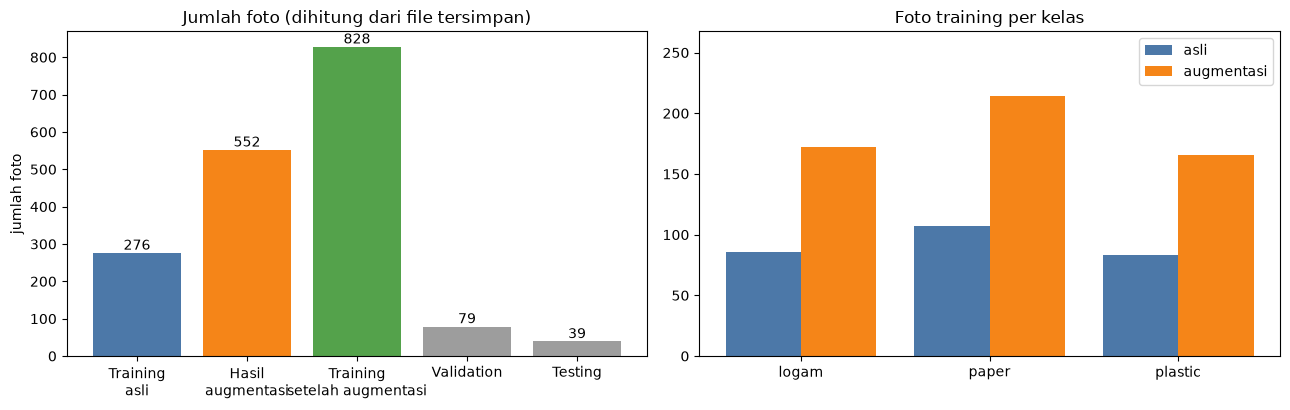

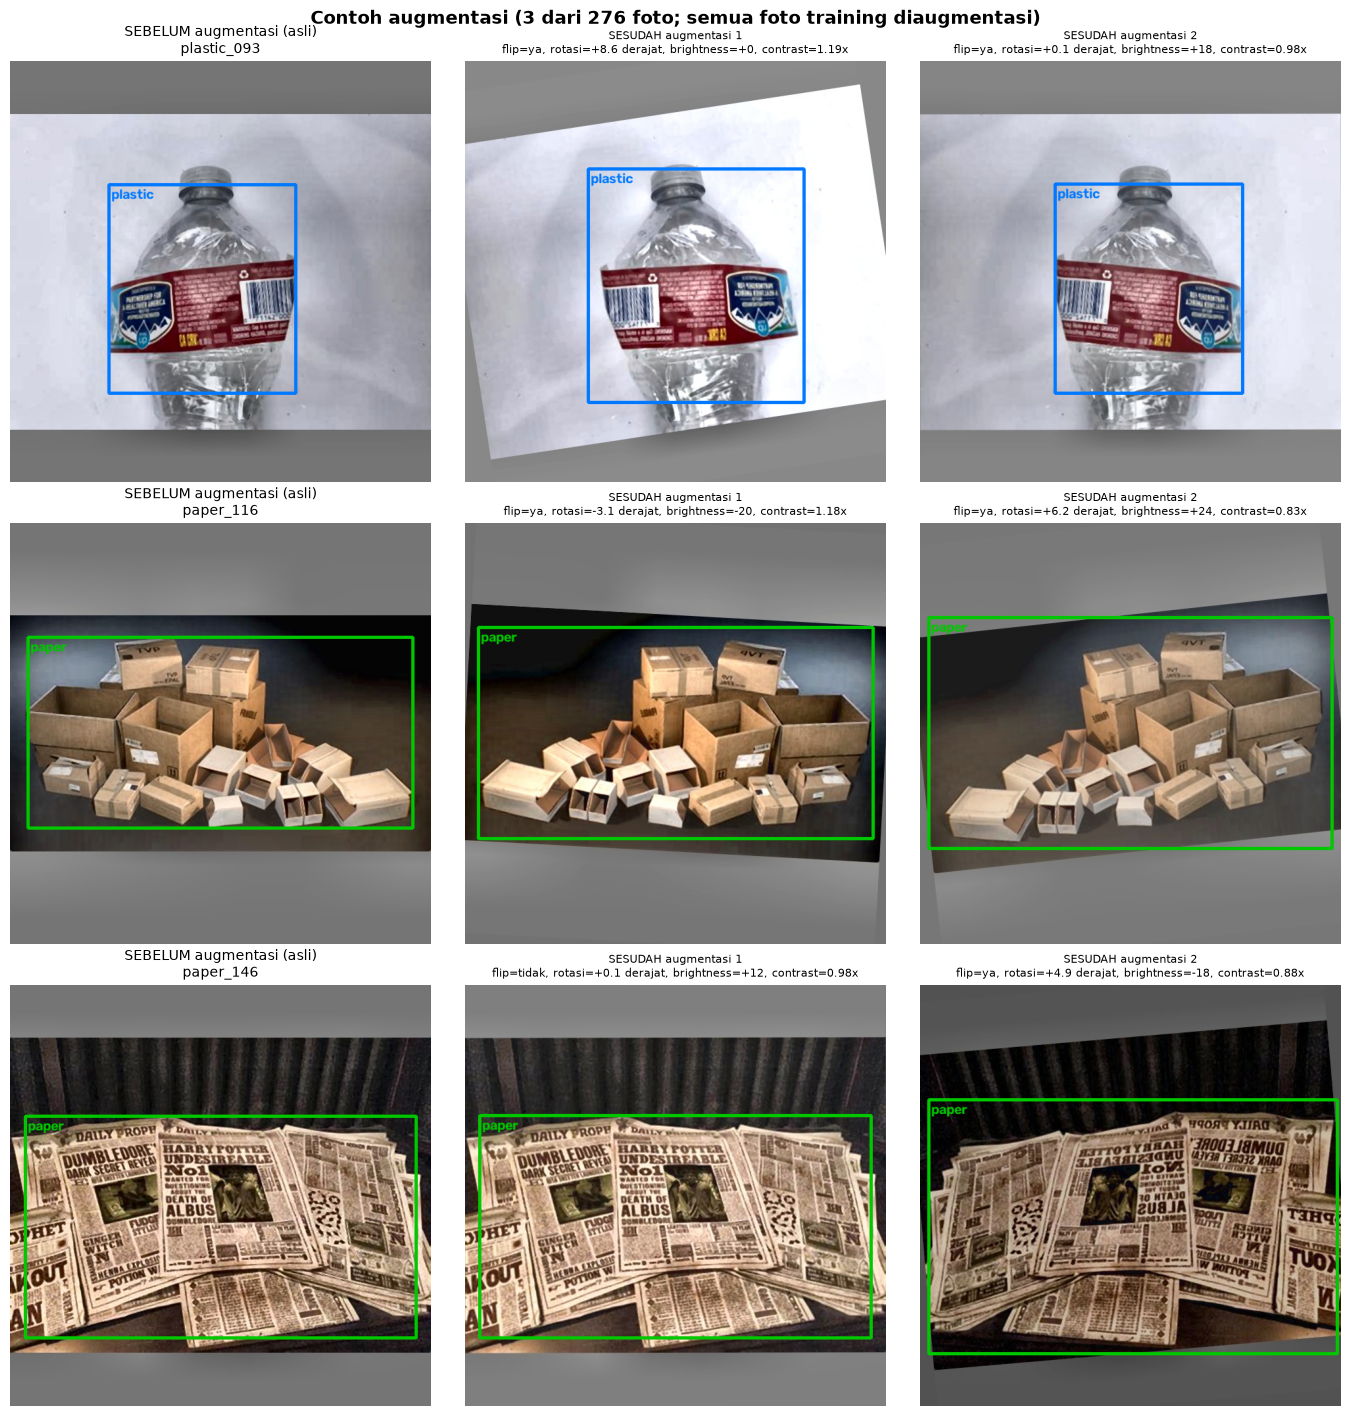

In [6]:
HASIL.mkdir(parents=True, exist_ok=True)

# Grafik jumlah foto
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
nama_bar = ["Training\nasli", "Hasil\naugmentasi", "Training\nsetelah augmentasi", "Validation", "Testing"]
nilai = [train_asli, train_aug, train_asli + train_aug, val_asli, test_asli]
batang = ax[0].bar(nama_bar, nilai, color=["#4c78a8", "#f58518", "#54a24b", "#9d9d9d", "#9d9d9d"])
ax[0].bar_label(batang)
ax[0].set_title("Jumlah foto (dihitung dari file tersimpan)")
ax[0].set_ylabel("jumlah foto")
posisi = np.arange(len(per_kelas))
ax[1].bar(posisi - 0.2, per_kelas["asli"], 0.4, label="asli", color="#4c78a8")
ax[1].bar(posisi + 0.2, per_kelas["augmentasi"], 0.4, label="augmentasi", color="#f58518")
ax[1].set_xticks(posisi)
ax[1].set_xticklabels(per_kelas["kelas"])
ax[1].set_title("Foto training per kelas")
ax[1].set_ylim(0, per_kelas[["asli", "augmentasi"]].values.max() * 1.25)
ax[1].legend()
fig.tight_layout()
fig.savefig(HASIL / "jumlah_augmentasi.png", dpi=120)
plt.show()

# Contoh sebelum / sesudah (dibatasi JUMLAH_CONTOH foto)
daftar = list(hasil_aug.keys())
pilih = np.random.default_rng(7).choice(len(daftar), min(JUMLAH_CONTOH, len(daftar)), replace=False)

fig, ax = plt.subplots(len(pilih), JUMLAH_AUG + 1, figsize=(4.6 * (JUMLAH_AUG + 1), 4.8 * len(pilih)), squeeze=False)
for a in ax.ravel():
    a.axis("off")
for i, idx in enumerate(pilih):
    stem = daftar[idx]
    img = baca(gambar_train / (stem + ".jpg"))
    kotak = baca_label(label_train / (stem + ".txt"), img.shape[:2])
    ax[i, 0].imshow(cv2.cvtColor(gambar_kotak(img, kotak), cv2.COLOR_BGR2RGB))
    ax[i, 0].set_title(f"SEBELUM augmentasi (asli)\n{stem}", fontsize=10)
    for j, (nama, info) in enumerate(hasil_aug[stem], start=1):
        aug = baca(gambar_train / (nama + ".jpg"))
        kotak_aug = baca_label(label_train / (nama + ".txt"), aug.shape[:2])
        ax[i, j].imshow(cv2.cvtColor(gambar_kotak(aug, kotak_aug), cv2.COLOR_BGR2RGB))
        ax[i, j].set_title(f"SESUDAH augmentasi {j}\n{info}", fontsize=8)
fig.suptitle(f"Contoh augmentasi ({len(pilih)} dari {len(hasil_aug)} foto; semua foto training diaugmentasi)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(HASIL / "contoh_augmentasi.png", dpi=120)
plt.show()